# Setup

In [1]:
import os
import json 
import numpy as np
from util import get_velocity_and_acceleration, load_keypoints_and_labels
from scipy.signal import find_peaks, peak_widths
import matplotlib.pyplot as plt
%matplotlib ipympl

In [8]:
# load preprocessed keypoints
recording_name = "pq1"
filename_stereo = os.path.join("data", recording_name, recording_name + "_stereo.npz")
filename_stereo_metadata = os.path.join("data", recording_name, recording_name + "_metadata.json")

filename_qualisys = os.path.join("data", recording_name, recording_name + "_qualisys.npz")

for filename in [filename_stereo, filename_stereo_metadata, filename_qualisys]:
    if not os.path.exists(filename):
        raise FileNotFoundError(f"File {filename} does not exist")


stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
print(f"shape: {stereo_keypoints.shape}")

qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)
print(f"shape: {qualisys_keypoints.shape}")

with open(filename_stereo_metadata) as f:
    stereo_metadata = json.load(f)

loaded data from: data\pq1\pq1_stereo.npz with keys: ['labels', 'keypoints']
shape: (6422, 19, 3)
loaded data from: data\pq1\pq1_qualisys.npz with keys: ['labels', 'keypoints']
shape: (6887, 10, 3)


# Segment pulls

In [9]:
def get_axis_velocity(keypoint, axis=None, fps=100):
    delta_t = 1 / fps  # frames/sec
    if axis is not None:
        keypoint = keypoint[:, axis]  # point, meters
    velocity = np.gradient(keypoint, delta_t, axis=0)  # vector, m/s
    return velocity


def get_pull_onsets(velocity, fps=100, height=0.5, min_interval=1.5):
    """Peaks of the velocity along the pull axis and the zero crossings before them.
    height: minimum peak velocity (m/s); min_interval: minimum time between pulls (s).
    Returns peaks and left_bases (pull onsets) as sample indices; each left base is the sample
    closest to the zero crossing, which peak_widths interpolates between samples."""
    peak_indices, _ = find_peaks(velocity, height=height, distance=int(min_interval * fps))

    # with prominence = peak velocity and rel_height=1, peak_widths measures the width at velocity 0;
    # the search limits are the whole signal, so it stops only at the first sample <= 0
    prominences = velocity[peak_indices]
    left_search_limits = np.zeros_like(peak_indices)
    right_search_limits = np.full_like(peak_indices, len(velocity) - 1)
    _, _, left_bases, right_bases = peak_widths(
        velocity,
        peak_indices,
        rel_height=1.0,
        prominence_data=(prominences, left_search_limits, right_search_limits),
    )
    left_base_indices = np.rint(left_bases).astype(int)
    right_base_indices = np.rint(right_bases).astype(int)
    return peak_indices, left_base_indices, right_base_indices

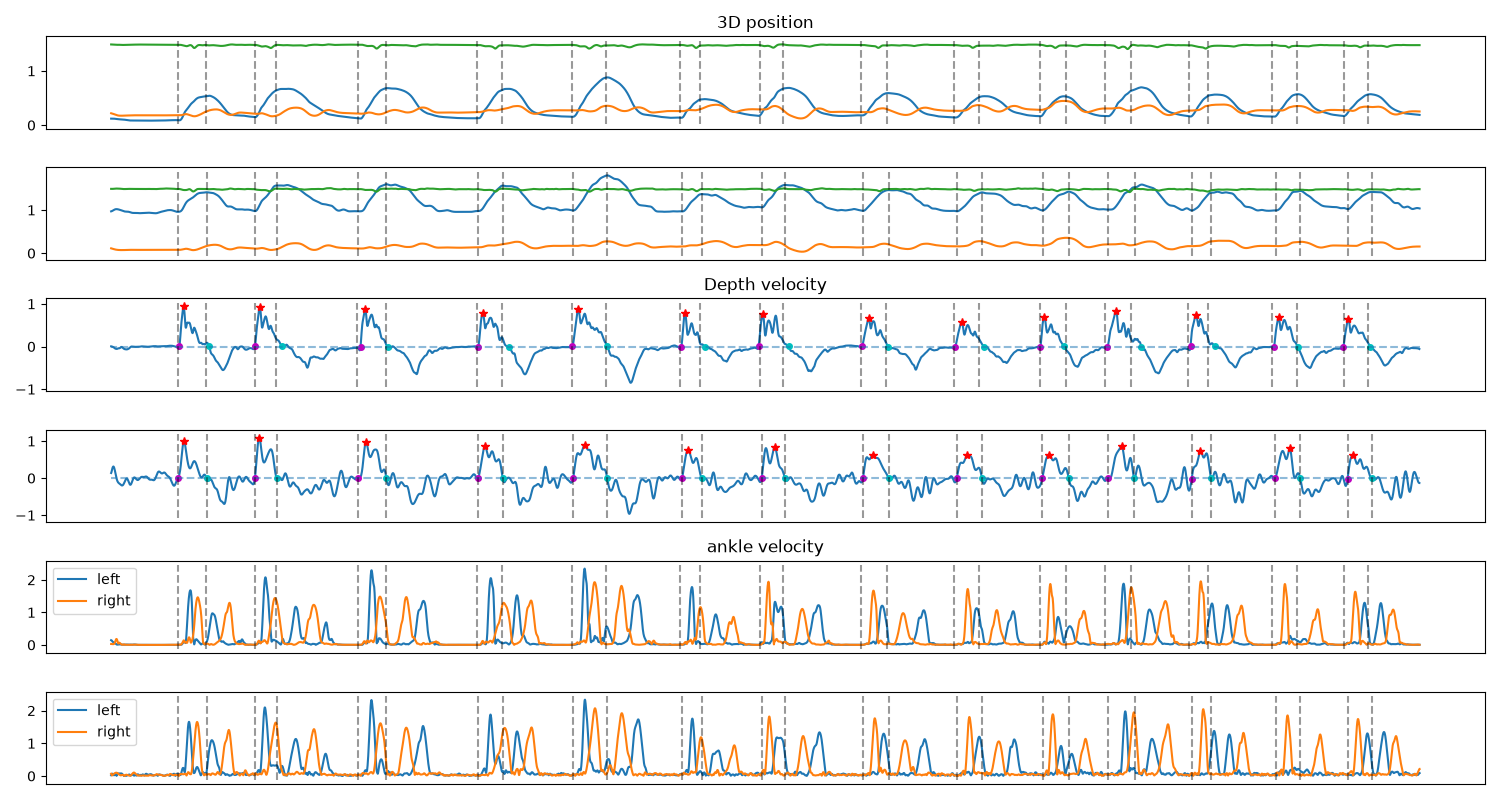

In [10]:
# 3D velocity & acceleration

stereo_cut = 390
qualisys_cut = 6050

qualisys_shoulder = qualisys_keypoints[:qualisys_cut, qualisys_labels.index("mid_shoulder"), :]
stereo_shoulder = stereo_keypoints[stereo_cut:, stereo_labels.index("mid_shoulder"), :]

qualisys_shoulder_velocity = get_axis_velocity(qualisys_shoulder, 0, 100)
stereo_shoulder_velocity = get_axis_velocity(stereo_shoulder, 0, 100)

stereo_left_ankle = stereo_keypoints[stereo_cut:, stereo_labels.index("left_ankle"), :]
qualisys_left_ankle = qualisys_keypoints[:qualisys_cut, qualisys_labels.index("left_ankle"), :]
stereo_right_ankle = stereo_keypoints[stereo_cut:, stereo_labels.index("right_ankle"), :]
qualisys_right_ankle = qualisys_keypoints[:qualisys_cut, qualisys_labels.index("right_ankle"), :]

qualisys_left_ankle_velocity = np.linalg.norm(get_axis_velocity(qualisys_left_ankle, None, 100), axis=1)
stereo_left_ankle_velocity = np.linalg.norm(get_axis_velocity(stereo_left_ankle, None, 100), axis=1)
qualisys_right_ankle_velocity = np.linalg.norm(get_axis_velocity(qualisys_right_ankle, None, 100), axis=1)
stereo_right_ankle_velocity = np.linalg.norm(get_axis_velocity(stereo_right_ankle, None, 100), axis=1)

stereo_peak_indices, stereo_starts, stereo_ends = get_pull_onsets(velocity=stereo_shoulder_velocity)
qualisys_peak_indices, qualisys_starts, qualisys_ends = get_pull_onsets(velocity=qualisys_shoulder_velocity)


if True:
    plt.close("all")
    fig, axs = plt.subplots(6, 1, figsize=(15, 8))

    axs[0].set_title("3D position")
    axs[0].plot(qualisys_shoulder, label=["depth", "vertical", "horizontal"])
    axs[1].plot(stereo_shoulder)

    axs[2].set_title("Depth velocity")
    axs[2].plot(qualisys_shoulder_velocity)
    axs[2].plot(qualisys_peak_indices, qualisys_shoulder_velocity[qualisys_peak_indices], "r*")
    axs[2].plot(qualisys_starts, qualisys_shoulder_velocity[qualisys_starts], "mo", markersize=4)
    axs[2].plot(qualisys_ends, qualisys_shoulder_velocity[qualisys_ends], "co", markersize=4)    
    axs[2].hlines(0, len(qualisys_shoulder_velocity), 0, linestyle="--", alpha=0.5)

    axs[3].plot(stereo_shoulder_velocity)
    axs[3].plot(stereo_peak_indices, stereo_shoulder_velocity[stereo_peak_indices], "r*")
    axs[3].plot(stereo_starts, stereo_shoulder_velocity[stereo_starts], "mo", markersize=4)
    axs[3].plot(stereo_ends, stereo_shoulder_velocity[stereo_ends], "co", markersize=4)
    axs[3].hlines(0, len(stereo_shoulder_velocity), 0, linestyle="--", alpha=0.5)

    axs[4].set_title("ankle velocity")
    axs[4].plot(qualisys_left_ankle_velocity, label="left")
    axs[4].plot(qualisys_right_ankle_velocity, label="right")
    axs[4].legend(loc="upper left")
    axs[5].plot(stereo_left_ankle_velocity, label="left")
    axs[5].plot(stereo_right_ankle_velocity, label="right")
    axs[5].legend(loc="upper left")
    for ax in axs:
        ax.set_xticks([])
        ax_ymin, ax_ymax = ax.get_ylim()
        for start, end in zip(stereo_starts, stereo_ends):
            ax.vlines(start, ax_ymin, ax_ymax, color="k", linestyles="--", alpha=0.4)
            ax.vlines(end, ax_ymin, ax_ymax, color="k", linestyles="--", alpha=0.4)

    plt.tight_layout()

In [ ]:
from dataclasses import dataclass
from typing import Literal


@dataclass
class GaitEvent:
    """
    Dataclass to store data related to a single Gait Event.

    Attributes:
        kind: Initial Contact (IC) or Final Contact (FC)
        frame: point of time (frame) at which the event occured
        side: foot (left/right) the event belongs to
        perspective: perspective (front/back) of segment to which the event belong to
        segment: indicates whether the segment contains straight walking or turning action
        segment_index: index of segment (starting from 0 at the beginning of recording). Incremented with perspective change
        relative_position: position of the event within the segment, relative to the segment's end (1=segment start in time, 0=segment end)
    """

    kind: Literal["IC", "FC"]
    frame: int
    side: Literal["left", "right"]
    perspective: Literal["front", "back"] | None = None
    segment: Literal["straight", "turn"] | None = None
    segment_index: int | None = None
    relative_position: float | None = None

    def __str__(self):
        # one table row; str() so that None fields can be padded
        fields = [self.kind, self.side, self.frame, self.perspective, self.segment, self.segment_index, self.relative_position]
        return "".join(f"{str(field):<10}" for field in fields)


class Pull:
    def __init__(self, start, end):
        self.start = start
        self.end = end
        self.gait_events: list[GaitEvent] = []  # gait events that belong to this pull